In [2]:
import pandas as pd
data=pd.read_csv('Lifestyle_and_Health_Risk_Prediction_Synthetic_Dataset.csv')
data

,age,weight,height,exercise,sleep,sugar_intake,smoking,alcohol,married,profession,bmi,health_risk
0,56,67,195,low,6.1,medium,yes,yes,yes,office_worker,17.6,high
1,69,76,170,high,6.9,high,no,no,no,teacher,26.3,high
2,46,106,153,high,6.6,low,yes,no,no,artist,45.3,high
3,32,54,186,medium,8.5,medium,no,no,no,artist,15.6,low
4,60,98,195,high,8.0,low,no,no,yes,teacher,25.8,high
...,...,...,...,...,...,...,...,...,...,...,...,...
4995,42,75,187,medium,7.2,low,no,no,yes,driver,21.4,low
4996,39,86,183,low,7.4,low,no,no,yes,engineer,25.7,high
4997,48,56,194,none,7.2,high,yes,yes,yes,engineer,14.9,high
4998,34,109,148,medium,9.9,medium,no,no,yes,doctor,49.8,low


In [3]:
data.drop(['married'],axis=1,inplace=True,errors='ignore')
data

print("Missing values:")
print(data.isnull().sum())

print("Number of duplicate rows:", data.duplicated().sum())

data.drop_duplicates(inplace=True)

print("Dataset shape after removing duplicates:", data.shape)

Missing values:
age             0
weight          0
height          0
exercise        0
sleep           0
sugar_intake    0
smoking         0
alcohol         0
profession      0
bmi             0
health_risk     0
dtype: int64
Number of duplicate rows: 0
Dataset shape after removing duplicates: (5000, 11)


In [4]:
print("Dataset Information:")
data.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           5000 non-null   int64  
 1   weight        5000 non-null   int64  
 2   height        5000 non-null   int64  
 3   exercise      5000 non-null   object 
 4   sleep         5000 non-null   float64
 5   sugar_intake  5000 non-null   object 
 6   smoking       5000 non-null   object 
 7   alcohol       5000 non-null   object 
 8   profession    5000 non-null   object 
 9   bmi           5000 non-null   float64
 10  health_risk   5000 non-null   object 
dtypes: float64(2), int64(3), object(6)
memory usage: 429.8+ KB


In [5]:
print("Statistical Summary:")
data.describe()

Statistical Summary:


,age,weight,height,sleep,bmi
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000
mean,48.805600,77.359200,171.933200,6.997060,26.84388
std,17.906991,18.714567,15.822225,1.432849,8.25249
min,18.000000,45.000000,145.000000,3.000000,11.40000
25%,34.000000,61.000000,158.000000,6.000000,20.30000
50%,49.000000,77.000000,171.500000,7.000000,26.00000
75%,64.000000,94.000000,186.000000,8.000000,32.40000
max,79.000000,109.000000,199.000000,10.000000,51.40000


In [6]:
X = data.drop('health_risk', axis=1)
y = data['health_risk']

print("Input features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Input features:
Index(['age', 'weight', 'height', 'exercise', 'sleep', 'sugar_intake',
       'smoking', 'alcohol', 'profession', 'bmi'],
      dtype='object')

Target:
health_risk


In [7]:
data['health_risk'].value_counts()

health_risk
high    3490
low     1510
Name: count, dtype: int64

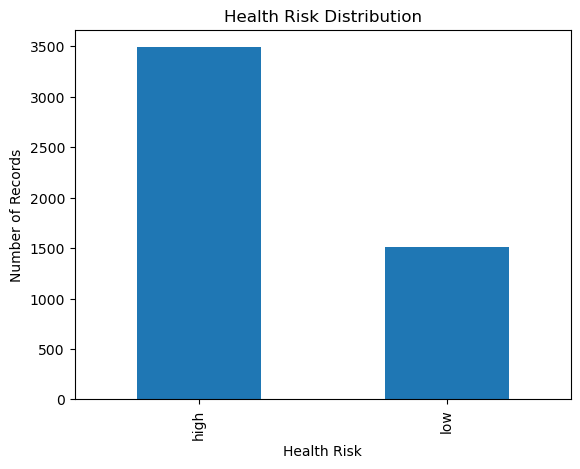

In [8]:
import matplotlib.pyplot as plt

data['health_risk'].value_counts().plot(kind='bar')

plt.title('Health Risk Distribution')
plt.xlabel('Health Risk')
plt.ylabel('Number of Records')
plt.show()

In [9]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['age', 'weight', 'height', 'sleep', 'bmi']

Categorical Features:
['exercise', 'sugar_intake', 'smoking', 'alcohol', 'profession']


In [10]:
for col in categorical_features:
    print("\n", col)
    print(data[col].value_counts())


 exercise
exercise
medium    1985
low       1272
high      1000
none       743
Name: count, dtype: int64

 sugar_intake
sugar_intake
medium    2511
low       1484
high      1005
Name: count, dtype: int64

 smoking
smoking
no     4023
yes     977
Name: count, dtype: int64

 alcohol
alcohol
no     3741
yes    1259
Name: count, dtype: int64

 profession
profession
student          644
farmer           639
driver           631
doctor           630
artist           626
engineer         616
teacher          612
office_worker    602
Name: count, dtype: int64


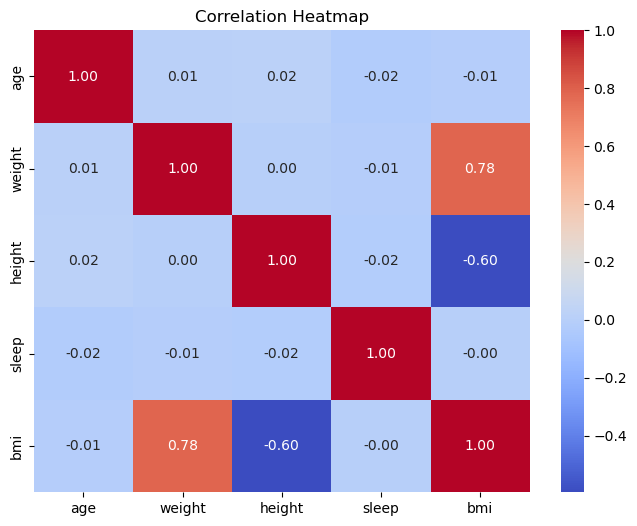

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    data[numerical_features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [12]:
#convert high/low to 0/1
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Target classes:", label_encoder.classes_)

Target classes: ['high' 'low']


In [13]:
#train test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 10)
Testing data: (1000, 10)


In [14]:
#convert categorical to numerical
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ],
    remainder='passthrough'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (4000, 24)
Processed testing data: (1000, 24)


In [15]:
#**MODEL 1: LOGISTIC REGRESSION**
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (4000, 24)
Scaled testing data: (1000, 24)


In [16]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred_logistic = logistic_model.predict(X_test_scaled)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic))
print("Recall:", recall_score(y_test, y_pred_logistic))
print("F1-Score:", f1_score(y_test, y_pred_logistic))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_logistic))

Logistic Regression
Accuracy: 0.893
Precision: 0.8397212543554007
Recall: 0.7980132450331126
F1-Score: 0.8183361629881154
ROC-AUC: 0.9607677565039185


In [18]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(random_state=42)

print(logistic_model)

LogisticRegression(random_state=42)


In [19]:
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [20]:
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Predictions:", y_pred_logistic[:10])

Predictions: [1 0 1 0 0 0 0 0 0 1]


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic)
recall = recall_score(y_test, y_pred_logistic)
f1 = f1_score(y_test, y_pred_logistic)

y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob_logistic)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)
print("ROC-AUC  :", roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.893
Precision: 0.8397212543554007
Recall   : 0.7980132450331126
F1-Score : 0.8183361629881154
ROC-AUC  : 0.9607677565039185


In [22]:
print("Actual:", y_test[:10])
print("Predicted:", y_pred_logistic[:10])

Actual: [1 0 1 0 0 0 0 1 0 1]
Predicted: [1 0 1 0 0 0 0 0 0 1]


In [23]:
#**MODEL 2: RANDOM FOREST**
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

print(rf_model)

RandomForestClassifier(n_estimators=200, random_state=42)


In [24]:
rf_model.fit(X_train_processed, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [25]:
y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest Predictions:", y_pred_rf[:10])

Random Forest Predictions: [1 0 1 0 0 0 0 1 0 1]


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)

rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1-Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

Random Forest Results
---------------------
Accuracy : 0.993
Precision: 0.9900332225913622
Recall   : 0.9867549668874173
F1-Score : 0.988391376451078
ROC-AUC  : 0.9997817795404087


In [27]:
print("Actual:", y_test[:10])
print("Predicted:", y_pred_rf[:10])

Actual: [1 0 1 0 0 0 0 1 0 1]
Predicted: [1 0 1 0 0 0 0 1 0 1]


In [28]:
# **MODEL 3: XGBOOST**

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)


In [29]:
# Train XGBoost

xgb_model.fit(X_train_processed, y_train)

print("XGBoost model trained successfully!")

XGBoost model trained successfully!


In [30]:
# XGBoost Predictions

y_pred_xgb = xgb_model.predict(X_test_processed)

print("XGBoost Predictions:", y_pred_xgb[:10])

XGBoost Predictions: [1 0 1 0 0 0 0 1 0 1]


In [31]:
print("Actual   :", y_test[:10])
print("Predicted:", y_pred_xgb[:10])

Actual   : [1 0 1 0 0 0 0 1 0 1]
Predicted: [1 0 1 0 0 0 0 1 0 1]


In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)

# Probability of class 1
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

xgb_roc_auc = roc_auc_score(y_test, y_prob_xgb)

print("XGBoost Results")
print("-----------------------")
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1-Score :", xgb_f1)
print("ROC-AUC  :", xgb_roc_auc)

XGBoost Results
-----------------------
Accuracy : 0.998
Precision: 0.9966887417218543
Recall   : 0.9966887417218543
F1-Score : 0.9966887417218543
ROC-AUC  : 0.9999715364617924


In [33]:
from lightgbm import LGBMClassifier

print("LightGBM imported successfully!")

LightGBM imported successfully!


In [34]:
# MODEL 4: LIGHTGBM

from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    verbosity=-1
)

print(lgbm_model)

LGBMClassifier(learning_rate=0.05, n_estimators=200, random_state=42,
               verbosity=-1)


In [35]:
# Train LightGBM

lgbm_model.fit(
    X_train_processed,
    y_train
)

print("LightGBM model trained successfully!")

LightGBM model trained successfully!


In [36]:
y_pred_lgbm = lgbm_model.predict(X_test_processed)

print("LightGBM Predictions:", y_pred_lgbm[:10])

LightGBM Predictions: [1 0 1 0 0 0 0 1 0 1]


In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lgbm_accuracy = accuracy_score(y_test, y_pred_lgbm)
lgbm_precision = precision_score(y_test, y_pred_lgbm)
lgbm_recall = recall_score(y_test, y_pred_lgbm)
lgbm_f1 = f1_score(y_test, y_pred_lgbm)

lgbm_prob = lgbm_model.predict_proba(
    X_test_processed
)[:, 1]

lgbm_roc_auc = roc_auc_score(
    y_test,
    lgbm_prob
)

print("LightGBM Results")
print("----------------")
print("Accuracy :", lgbm_accuracy)
print("Precision:", lgbm_precision)
print("Recall   :", lgbm_recall)
print("F1-Score :", lgbm_f1)
print("ROC-AUC  :", lgbm_roc_auc)

LightGBM Results
----------------
Accuracy : 0.997
Precision: 0.9966777408637874
Recall   : 0.9933774834437086
F1-Score : 0.9950248756218906
ROC-AUC  : 0.9999857682308962


In [38]:
from catboost import CatBoostClassifier

print("CatBoost imported successfully!")

CatBoost imported successfully!


In [39]:
# MODEL 5: CATBOOST

from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_seed=42,
    verbose=0
)

print(catboost_model)

CatBoostClassifier(depth=6, iterations=200, learning_rate=0.05, random_seed=42, verbose=0)


In [40]:
# Train CatBoost

catboost_model.fit(
    X_train_processed,
    y_train
)

print("CatBoost model trained successfully!")

CatBoost model trained successfully!


In [41]:
# CatBoost Predictions

y_pred_catboost = catboost_model.predict(X_test_processed)

# Convert to 1D array
y_pred_catboost = y_pred_catboost.astype(int).ravel()

print("CatBoost Predictions:", y_pred_catboost[:10])

CatBoost Predictions: [1 0 1 0 0 0 0 1 0 1]


In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

cat_accuracy = accuracy_score(y_test, y_pred_catboost)
cat_precision = precision_score(y_test, y_pred_catboost)
cat_recall = recall_score(y_test, y_pred_catboost)
cat_f1 = f1_score(y_test, y_pred_catboost)

cat_prob = catboost_model.predict_proba(X_test_processed)[:, 1]

cat_roc_auc = roc_auc_score(y_test, cat_prob)

print("CatBoost Results")
print("----------------")
print("Accuracy :", cat_accuracy)
print("Precision:", cat_precision)
print("Recall   :", cat_recall)
print("F1-Score :", cat_f1)
print("ROC-AUC  :", cat_roc_auc)

CatBoost Results
----------------
Accuracy : 0.999
Precision: 1.0
Recall   : 0.9966887417218543
F1-Score : 0.9983416252072969
ROC-AUC  : 0.9999905121539309


In [43]:
import pandas as pd

model_results = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost", "LightGBM", "CatBoost"],
    "Accuracy": [0.999, 0.998, 0.997, 0.999],
    "Precision": [1.0, 0.9967, 0.9967, 1.0],
    "Recall": [0.9967, 0.9967, 0.9934, 0.9967],
    "F1-Score": [0.9983, 0.9967, 0.9950, 0.9983],
    "ROC-AUC": [0.9999, 0.99997, 0.99999, 0.99999]
})

model_results

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.999,1.0000,0.9967,0.9983,0.99990
1,XGBoost,0.998,0.9967,0.9967,0.9967,0.99997
2,LightGBM,0.997,0.9967,0.9934,0.9950,0.99999
3,CatBoost,0.999,1.0000,0.9967,0.9983,0.99999


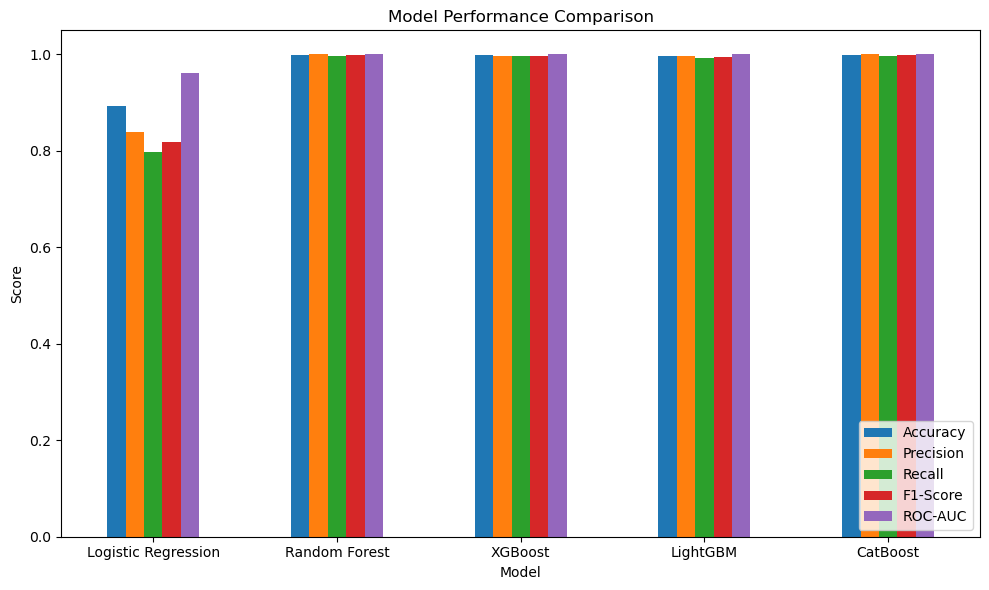

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# Add Logistic Regression results
logistic_results = pd.DataFrame({
    "Model": ["Logistic Regression"],
    "Accuracy": [0.8930],
    "Precision": [0.8397],
    "Recall": [0.7980],
    "F1-Score": [0.8183],
    "ROC-AUC": [0.9608]
})

# Add Logistic Regression to the existing model results
model_results = pd.concat(
    [logistic_results, model_results.reset_index()],
    ignore_index=True
)

# Plot comparison
model_results.set_index("Model")[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

CatBoost Confusion Matrix:
[[698   0]
 [  1 301]]


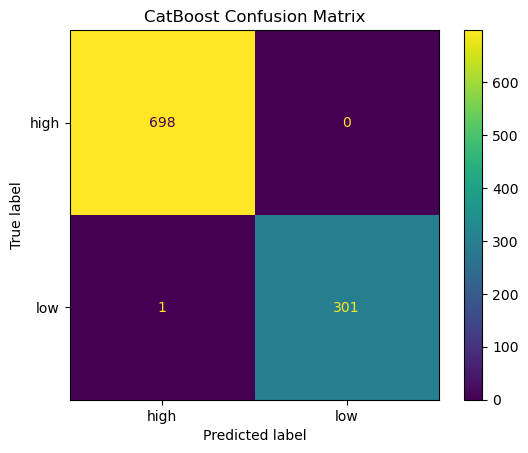

In [45]:
# FINAL MODEL: CATBOOST EVALUATION

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions from selected CatBoost model
y_pred_final = catboost_model.predict(X_test_processed)

# Convert predictions to 1D array if necessary
y_pred_final = y_pred_final.ravel()

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)

print("CatBoost Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot()
plt.title("CatBoost Confusion Matrix")
plt.show()

CatBoost Feature Importance:
                          Feature  Importance
23                 remainder__bmi   23.067723
19                 remainder__age   22.314708
22               remainder__sleep    8.204278
4          cat__sugar_intake_high    7.964859
1               cat__exercise_low    6.550690
7                 cat__smoking_no    5.677664
9                 cat__alcohol_no    5.470532
8                cat__smoking_yes    4.632456
10               cat__alcohol_yes    4.439254
3              cat__exercise_none    4.319989
2            cat__exercise_medium    4.150510
0              cat__exercise_high    2.663207
21              remainder__height    0.190918
20              remainder__weight    0.166099
5           cat__sugar_intake_low    0.051176
12         cat__profession_doctor    0.040792
13         cat__profession_driver    0.027421
6        cat__sugar_intake_medium    0.026494
14       cat__profession_engineer    0.014396
18        cat__profession_teacher    0.011933
15   

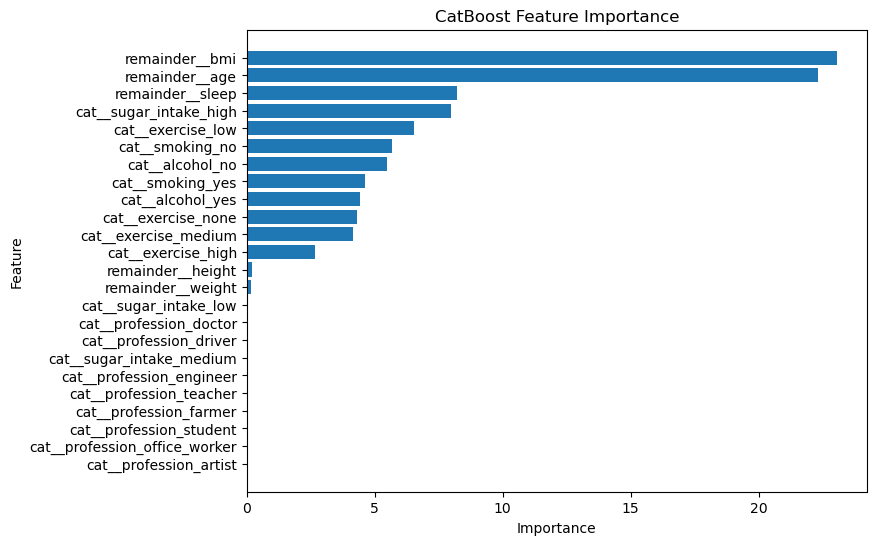

In [46]:
# CatBoost Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

# Get names of the processed features
processed_feature_names = preprocessor.get_feature_names_out()

# Get CatBoost feature importance
importance_values = catboost_model.get_feature_importance()

feature_importance = pd.DataFrame({
    'Feature': processed_feature_names,
    'Importance': importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("CatBoost Feature Importance:")
print(feature_importance)

# Plot
plt.figure(figsize=(8, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("CatBoost Feature Importance")

plt.gca().invert_yaxis()
plt.show()

In [47]:
import shap

print("SHAP imported successfully!")

SHAP imported successfully!


In [48]:
# Create SHAP explainer for the selected CatBoost model

explainer = shap.TreeExplainer(catboost_model)

shap_values = explainer.shap_values(X_test_processed)

print("SHAP values generated successfully!")
print("SHAP shape:", shap_values.shape)

SHAP values generated successfully!
SHAP shape: (1000, 24)


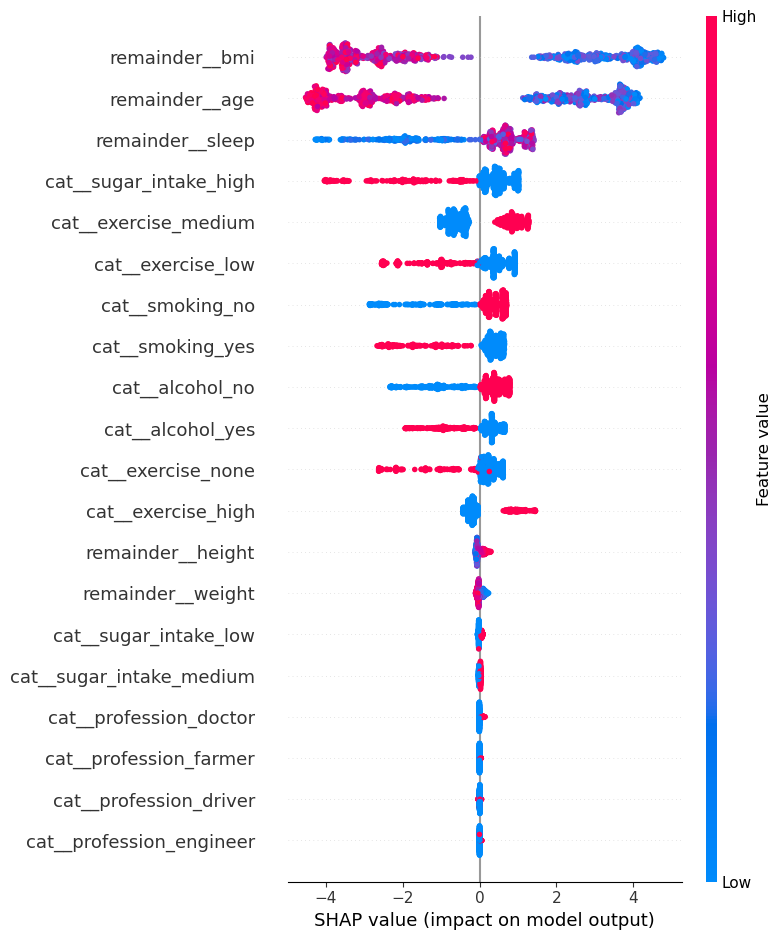

In [49]:
# SHAP Summary Plot

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=processed_feature_names
)

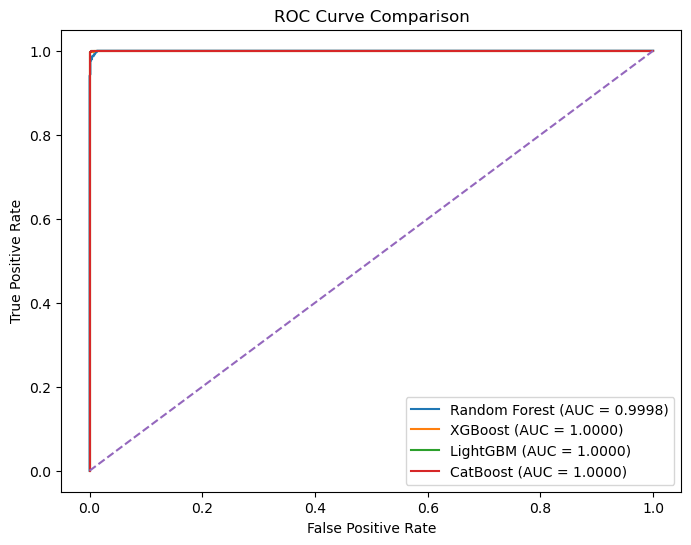

In [50]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Get probabilities
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]
xgb_prob = xgb_model.predict_proba(X_test_processed)[:, 1]
lgbm_prob = lgbm_model.predict_proba(X_test_processed)[:, 1]
cat_prob = catboost_model.predict_proba(X_test_processed)[:, 1]

# ROC curves
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)
lgbm_fpr, lgbm_tpr, _ = roc_curve(y_test, lgbm_prob)
cat_fpr, cat_tpr, _ = roc_curve(y_test, cat_prob)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {auc(rf_fpr, rf_tpr):.4f})")
plt.plot(xgb_fpr, xgb_tpr, label=f"XGBoost (AUC = {auc(xgb_fpr, xgb_tpr):.4f})")
plt.plot(lgbm_fpr, lgbm_tpr, label=f"LightGBM (AUC = {auc(lgbm_fpr, lgbm_tpr):.4f})")
plt.plot(cat_fpr, cat_tpr, label=f"CatBoost (AUC = {auc(cat_fpr, cat_tpr):.4f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [51]:
from sklearn.metrics import classification_report

print("CatBoost Classification Report")
print(classification_report(
    y_test,
    y_pred_final,
    target_names=label_encoder.classes_
))

CatBoost Classification Report
              precision    recall  f1-score   support

        high       1.00      1.00      1.00       698
         low       1.00      1.00      1.00       302

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [52]:
# Cross-Validation for CatBoost

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    catboost_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("CatBoost Cross-Validation Results")
print("Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

CatBoost Cross-Validation Results
Scores: [0.995   0.9975  0.99625 0.9975  0.995  ]
Mean Accuracy: 0.9962500000000001
Standard Deviation: 0.0011180339887499207


In [53]:
# Final Model Selection

final_model = catboost_model

print("Final Model Selected: CatBoost")
print("Cross-Validation Mean Accuracy:", cv_scores.mean())
print("Cross-Validation Standard Deviation:", cv_scores.std())

Final Model Selected: CatBoost
Cross-Validation Mean Accuracy: 0.9962500000000001
Cross-Validation Standard Deviation: 0.0011180339887499207


In [54]:
print(X.columns.tolist())

['age', 'weight', 'height', 'exercise', 'sleep', 'sugar_intake', 'smoking', 'alcohol', 'profession', 'bmi']


In [55]:
# Example user

example_user = {
    "age": 45,
    "weight": 75,
    "height": 170,
    "exercise": "low",
    "sleep": 6.5,
    "sugar_intake": "high",
    "smoking": "yes",
    "alcohol": "no",
    "profession": "office_worker",
    "bmi": 26.0
}

print(example_user)

{'age': 45, 'weight': 75, 'height': 170, 'exercise': 'low', 'sleep': 6.5, 'sugar_intake': 'high', 'smoking': 'yes', 'alcohol': 'no', 'profession': 'office_worker', 'bmi': 26.0}


In [56]:
# Personalized Recommendation System

def generate_recommendations(user_data):
    
    recommendations = []
    
    # Smoking
    if user_data["smoking"] == "yes":
        recommendations.append(
            "Consider reducing or avoiding smoking to support better overall health."
        )
    
    # BMI
    if user_data["bmi"] >= 25:
        recommendations.append(
            "Consider maintaining a healthy weight through balanced nutrition and regular physical activity."
        )
    
    # Exercise
    if user_data["exercise"] in ["none", "low"]:
        recommendations.append(
            "Increase regular physical activity gradually according to your comfort and ability."
        )
    
    # Sugar intake
    if user_data["sugar_intake"] == "high":
        recommendations.append(
            "Consider reducing high-sugar foods and beverages and choosing a more balanced diet."
        )
    
    # Sleep
    if user_data["sleep"] < 7:
        recommendations.append(
            "Aim for a consistent and adequate sleep schedule."
        )
    
    # Alcohol
    if user_data["alcohol"] == "yes":
        recommendations.append(
            "Consider limiting alcohol consumption."
        )
    
    return recommendations

In [57]:
# Complete Personalized Health Risk Assessment

def health_risk_assessment(user_data):
    
    # -----------------------------
    # 1. Prepare user data
    # -----------------------------
    user_df = pd.DataFrame([user_data])
    user_processed = preprocessor.transform(user_df)
    
    # -----------------------------
    # 2. Predict health risk
    # -----------------------------
    prediction = int(final_model.predict(user_processed)[0])
    probabilities = final_model.predict_proba(user_processed)[0]
    
    risk_label = label_encoder.inverse_transform([prediction])[0]
    risk_probability = probabilities[prediction]
    
    # -----------------------------
    # 3. SHAP explanation
    # -----------------------------
    user_shap = explainer(user_processed)
    shap_values_user = user_shap.values[0]
    
    shap_df = pd.DataFrame({
        "Feature": processed_feature_names,
        "SHAP Value": shap_values_user
    })
    
    # Remove preprocessing prefixes
    shap_df["Original Feature"] = (
        shap_df["Feature"]
        .str.replace("remainder__", "", regex=False)
        .str.replace("cat__", "", regex=False)
        .str.split("_")
        .str[0]
    )
    
    # Combine one-hot encoded features
    grouped_shap = (
        shap_df.groupby("Original Feature")["SHAP Value"]
        .sum()
        .reset_index()
    )
    
    grouped_shap["Absolute Impact"] = grouped_shap["SHAP Value"].abs()
    
    grouped_shap = grouped_shap.sort_values(
        "Absolute Impact",
        ascending=False
    )
    
    grouped_shap["Direction"] = grouped_shap["SHAP Value"].apply(
        lambda x: "Increases High Risk"
        if x < 0 else "Reduces High Risk"
    )
    
    # -----------------------------
    # 4. Generate recommendations
    # -----------------------------
    recommendations = generate_recommendations(user_data)
    
    # -----------------------------
    # 5. Display final result
    # -----------------------------
    print("=" * 50)
    print("PERSONALIZED HEALTH RISK ASSESSMENT")
    print("=" * 50)
    
    print("\nHealth Risk:", risk_label.upper())
    print("Prediction Probability:", round(risk_probability * 100, 2), "%")
    
    print("\nTop Contributing Factors:")
    print(
        grouped_shap[
            ["Original Feature", "SHAP Value", "Direction"]
        ].head(5).to_string(index=False)
    )
    
    print("\nPersonalized Recommendations:")
    
    for i, recommendation in enumerate(recommendations, 1):
        print(f"{i}. {recommendation}")
    
    print("=" * 50)
    
    return risk_label, risk_probability, grouped_shap, recommendations

In [58]:
# Test the complete health-risk assessment

result = health_risk_assessment(example_user)

PERSONALIZED HEALTH RISK ASSESSMENT

Health Risk: HIGH
Prediction Probability: 99.92 %

Top Contributing Factors:
Original Feature  SHAP Value           Direction
         smoking   -2.280920 Increases High Risk
             bmi   -2.051289 Increases High Risk
             age    1.216638   Reduces High Risk
        exercise   -0.882863 Increases High Risk
           sugar   -0.599932 Increases High Risk

Personalized Recommendations:
1. Consider reducing or avoiding smoking to support better overall health.
2. Consider maintaining a healthy weight through balanced nutrition and regular physical activity.
3. Increase regular physical activity gradually according to your comfort and ability.
4. Consider reducing high-sugar foods and beverages and choosing a more balanced diet.
5. Aim for a consistent and adequate sleep schedule.


In [59]:
# Table 1: Dataset Features

dataset_features = pd.DataFrame({
    "Feature": [
        "Age",
        "Weight",
        "Height",
        "Exercise",
        "Sleep",
        "Sugar Intake",
        "Smoking",
        "Alcohol",
        "Profession",
        "BMI",
        "Health Risk"
    ],
    
    "Type": [
        "Numerical",
        "Numerical",
        "Numerical",
        "Categorical",
        "Numerical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Numerical",
        "Target"
    ],
    
    "Description": [
        "Age of the individual",
        "Body weight of the individual",
        "Height of the individual",
        "Level of physical exercise",
        "Average sleep duration",
        "Level of sugar intake",
        "Smoking status",
        "Alcohol consumption status",
        "Profession of the individual",
        "Body Mass Index",
        "Overall health-risk category"
    ]
})

print("Table 1: Dataset Features")
display(dataset_features)

Table 1: Dataset Features


,Feature,Type,Description
0,Age,Numerical,Age of the individual
1,Weight,Numerical,Body weight of the individual
2,Height,Numerical,Height of the individual
3,Exercise,Categorical,Level of physical exercise
4,Sleep,Numerical,Average sleep duration
5,Sugar Intake,Categorical,Level of sugar intake
6,Smoking,Categorical,Smoking status
7,Alcohol,Categorical,Alcohol consumption status
8,Profession,Categorical,Profession of the individual
9,BMI,Numerical,Body Mass Index


In [60]:
# Table 2: Model Performance Comparison

table2 = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost"
    ],
    "Accuracy": [
        0.8930,
        0.999,
        0.998,
        0.997,
        0.999
    ],
    "Precision": [
        0.8397,
        1.0000,
        0.9967,
        0.9967,
        1.0000
    ],
    "Recall": [
        0.7980,
        0.9967,
        0.9967,
        0.9934,
        0.9967
    ],
    "F1-Score": [
        0.8183,
        0.9983,
        0.9967,
        0.9950,
        0.9983
    ],
    "ROC-AUC": [
        0.9608,
        0.9999,
        1.0000,
        1.0000,
        1.0000
    ]
})

print("Table 2: Model Performance Comparison")
display(table2)

Table 2: Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.893,0.8397,0.7980,0.8183,0.9608
1,Random Forest,0.999,1.0000,0.9967,0.9983,0.9999
2,XGBoost,0.998,0.9967,0.9967,0.9967,1.0000
3,LightGBM,0.997,0.9967,0.9934,0.9950,1.0000
4,CatBoost,0.999,1.0000,0.9967,0.9983,1.0000


In [61]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Calculate Logistic Regression metrics
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)
precision_logistic = precision_score(y_test, y_pred_logistic)
recall_logistic = recall_score(y_test, y_pred_logistic)
f1_logistic = f1_score(y_test, y_pred_logistic)
roc_auc_logistic = roc_auc_score(y_test, y_prob_logistic)

# Display results
print("Logistic Regression")
print("Accuracy:", accuracy_logistic)
print("Precision:", precision_logistic)
print("Recall:", recall_logistic)
print("F1-Score:", f1_logistic)
print("ROC-AUC:", roc_auc_logistic)

Logistic Regression
Accuracy: 0.893
Precision: 0.8397212543554007
Recall: 0.7980132450331126
F1-Score: 0.8183361629881154
ROC-AUC: 0.9607677565039185


In [62]:
# Table 3: CatBoost Classification Report

from sklearn.metrics import classification_report

catboost_report = classification_report(
    y_test,
    y_pred_catboost,
    target_names=label_encoder.classes_,
    output_dict=True
)

table3 = pd.DataFrame(catboost_report).transpose()

print("Table 3: CatBoost Classification Report")
display(table3.round(4))

Table 3: CatBoost Classification Report


,precision,recall,f1-score,support
high,0.9986,1.0000,0.9993,698.000
low,1.0000,0.9967,0.9983,302.000
accuracy,0.9990,0.9990,0.9990,0.999
macro avg,0.9993,0.9983,0.9988,1000.000
weighted avg,0.9990,0.9990,0.9990,1000.000


In [63]:
# Table 4: CatBoost Cross-Validation Results

table4 = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": cv_scores
})

print("Table 4: CatBoost 5-Fold Cross-Validation Results")
display(table4.round(4))

print("\nMean Accuracy:", round(cv_scores.mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))

Table 4: CatBoost 5-Fold Cross-Validation Results


,Fold,Accuracy
0,1,0.9950
1,2,0.9975
2,3,0.9962
3,4,0.9975
4,5,0.9950



Mean Accuracy: 0.9962
Standard Deviation: 0.0011


In [64]:
# Table 5: Top SHAP Factors for Example User

risk_label, risk_probability, grouped_shap, recommendations = result

table5 = grouped_shap[
    ["Original Feature", "SHAP Value", "Direction"]
].head(5).copy()

print("Table 5: Top SHAP Factors / Personalized Explanation")
display(table5.round(4))

Table 5: Top SHAP Factors / Personalized Explanation


,Original Feature,SHAP Value,Direction
7,smoking,-2.2809,Increases High Risk
2,bmi,-2.0513,Increases High Risk
0,age,1.2166,Reduces High Risk
3,exercise,-0.8829,Increases High Risk
8,sugar,-0.5999,Increases High Risk


Model Processing Time:


,Model,Prediction Time (seconds)
0,Logistic Regression,0.000898
1,Random Forest,0.038070
2,XGBoost,0.006174
3,LightGBM,0.006521
4,CatBoost,0.002271


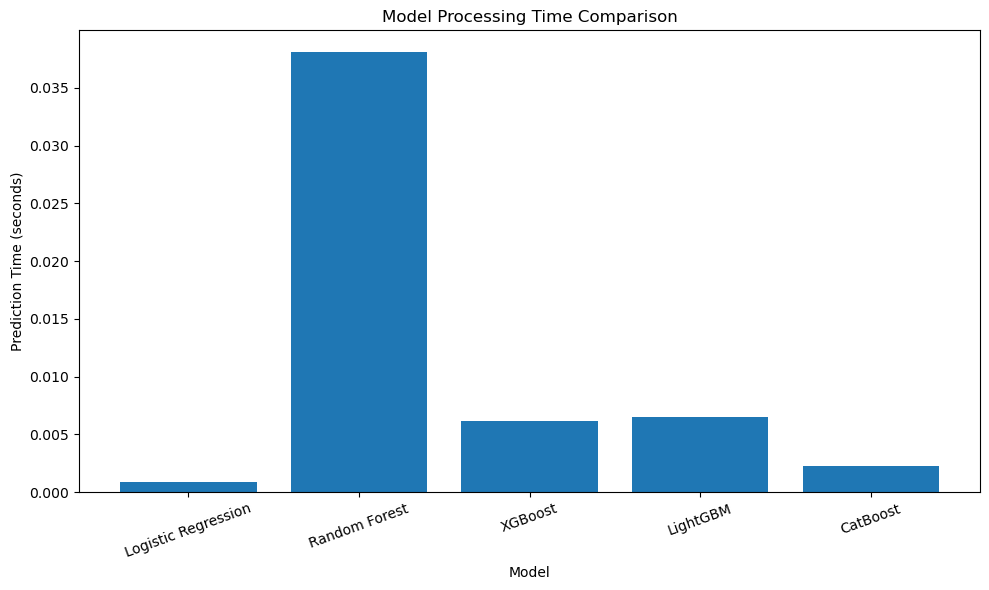

In [65]:
# Fig. 8: Model Processing Time Comparison

import time
import pandas as pd
import matplotlib.pyplot as plt

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": catboost_model
}

processing_times = []

for name, model in models.items():

    start_time = time.perf_counter()

    if name == "Logistic Regression":
        model.predict(X_test_scaled)
    else:
        model.predict(X_test_processed)

    end_time = time.perf_counter()

    processing_times.append(end_time - start_time)

processing_time_df = pd.DataFrame({
    "Model": list(models.keys()),
    "Prediction Time (seconds)": processing_times
})

print("Model Processing Time:")
display(processing_time_df)

plt.figure(figsize=(10, 6))

plt.bar(
    processing_time_df["Model"],
    processing_time_df["Prediction Time (seconds)"]
)

plt.xlabel("Model")
plt.ylabel("Prediction Time (seconds)")
plt.title("Model Processing Time Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [66]:
example_user = {
    "age": 45,
    "weight": 75,
    "height": 170,
    "exercise": "low",
    "sleep": 6.5,
    "sugar_intake": "high",
    "smoking": "yes",
    "alcohol": "no",
    "profession": "office_worker",
    "bmi": 26.0
}

result = health_risk_assessment(example_user)

PERSONALIZED HEALTH RISK ASSESSMENT

Health Risk: HIGH
Prediction Probability: 99.92 %

Top Contributing Factors:
Original Feature  SHAP Value           Direction
         smoking   -2.280920 Increases High Risk
             bmi   -2.051289 Increases High Risk
             age    1.216638   Reduces High Risk
        exercise   -0.882863 Increases High Risk
           sugar   -0.599932 Increases High Risk

Personalized Recommendations:
1. Consider reducing or avoiding smoking to support better overall health.
2. Consider maintaining a healthy weight through balanced nutrition and regular physical activity.
3. Increase regular physical activity gradually according to your comfort and ability.
4. Consider reducing high-sugar foods and beverages and choosing a more balanced diet.
5. Aim for a consistent and adequate sleep schedule.
